# Pipe leak prediction: random forest versus XGBoost

Notebook 05 has prepared the data and selected two of the four candidate groups.
This notebook reads its numerical CSVs, tunes **random forest and XGBoost**, and
chooses the model with the higher mean ROC-AUC across **2025 and 2026**.

After comparison, refit the winning family on all labelled 2020–2026 rows and
save `results/model_comparison/best_model.joblib`. There are no future-year predictions.
All encoding, imputation and feature selection remain in Notebook 03.

**Saved run:** xgboost wins on mean ROC-AUC, **0.8638**, across the two evaluation years.

## 1. Setup and read the prepared data
ID, year and target are metadata. All other CSV columns are model inputs. Two
selected groups can produce more than two columns if material/surface is selected.

**Python environment:** choose the `Python (STAT 440 .venv)` kernel.

In [1]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, PredefinedSplit
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score,
                             precision_score, recall_score, brier_score_loss,
                             precision_recall_curve, roc_curve, confusion_matrix)
from sklearn.calibration import calibration_curve
from xgboost import XGBClassifier
from IPython.display import display, Markdown

project_dir = Path.cwd()
if project_dir.name == "nds":
    project_dir = project_dir.parent
data_dir = project_dir / "data"
fold_dir = data_dir / "model_folds"
output_dir = project_dir / "results" / "model_comparison"
output_dir.mkdir(parents=True, exist_ok=True)
random_seed = 440
evaluation_years = [2025, 2026]
metadata_columns = ["pipe_id", "year", "target"]
plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 11})

In [2]:
training_data = pd.read_csv(data_dir / "model_training_data.csv")
final_predictors = training_data.columns.drop(metadata_columns).tolist()
print(f"Full training rows: {len(training_data):,}; numerical inputs: {len(final_predictors)}")
print("Input columns:", final_predictors)
display(training_data.head())

Full training rows: 250,776; numerical inputs: 2
Input columns: ['adjusted_age', 'network_rate_75m']


,pipe_id,year,target,adjusted_age,network_rate_75m
0,P01001,2020,0,64.808743,0.084042
1,P01002,2020,0,48.284153,0.021719
2,P01003,2020,0,48.286885,0.020049
3,P01004,2020,0,37.612022,0.023694
4,P01005,2020,0,48.497268,0.023694


## 2. Use two chronological evaluations
For test year Y, tune on training years 2020–Y−2 and validation Y−1. Then refit
on all earlier rows through Y−1 before evaluating Y. The prepared files already
use the matching training-only medians and selected feature groups.

These two years provide a compact comparison, with less evidence about stability
than five test years. Both years were explored earlier in this project, so results
are reused development evidence rather than an untouched test-set estimate.

In [3]:
display(pd.DataFrame({
    "Test year": evaluation_years,
    "Inner training": ["2020–2023", "2020–2024"],
    "Inner validation": [2024, 2025],
    "Refit training": ["2020–2024", "2020–2025"]
}))

def load_fold(year):
    year_dir = fold_dir / str(year)
    inner = pd.read_csv(year_dir / "inner_train.csv.gz")
    validation = pd.read_csv(year_dir / "validation.csv.gz")
    training = pd.read_csv(year_dir / "train.csv.gz")
    testing = pd.read_csv(year_dir / "test.csv.gz")
    predictors = training.columns.drop(metadata_columns).tolist()
    return inner, validation, training, testing, predictors

,Test year,Inner training,Inner validation,Refit training
0,2025,2020–2023,2024,2020–2024
1,2026,2020–2024,2025,2020–2025


## 3. Metrics and classification thresholds
The primary criterion is mean annual ROC-AUC. Also report average precision,
F1, precision, recall and Brier score. Choose F1 thresholds using the earlier
validation year, then freeze them before scoring the test year.

In [4]:
def choose_threshold(target, probabilities):
    precision, recall, thresholds = precision_recall_curve(target, probabilities)
    f1 = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-12)
    return thresholds[np.argmax(f1)]

def evaluate_model(target, probabilities, threshold):
    predictions = probabilities >= threshold
    return {"roc_auc": roc_auc_score(target, probabilities),
            "average_precision": average_precision_score(target, probabilities),
            "f1": f1_score(target, predictions, zero_division=0),
            "precision": precision_score(target, predictions, zero_division=0),
            "recall": recall_score(target, predictions, zero_division=0),
            "brier": brier_score_loss(target, probabilities)}

In [5]:
evaluation_rows = []
historical_predictions = []
tuning_rows = []

def record_predictions(model_name, year, testing, probabilities, threshold):
    predictions = testing[["pipe_id", "year", "target"]].copy()
    predictions["model"] = model_name
    predictions["probability"] = probabilities
    predictions["threshold"] = threshold
    historical_predictions.append(predictions)
    scores = evaluate_model(testing["target"], probabilities, threshold)
    evaluation_rows.append({"model": model_name, "year": year, **scores})
    print(f"{year} {model_name}: AUC {scores['roc_auc']:.4f}, F1 {scores['f1']:.4f}")

## 4. Tune and evaluate random forest
Try six configurations. GridSearchCV uses the predefined earlier validation year,
not shuffled folds. Select ROC-AUC first and average precision to break ties.

In [6]:
forest_settings = [
    dict(n_estimators=128, max_depth=6, min_samples_leaf=60, max_features=1.0, class_weight=None),
    dict(n_estimators=160, max_depth=10, min_samples_leaf=30, max_features=0.7, class_weight=None),
    dict(n_estimators=160, max_depth=14, min_samples_leaf=20, max_features=0.7, class_weight=None),
    dict(n_estimators=160, max_depth=None, min_samples_leaf=60, max_features=1.0, class_weight=None),
    dict(n_estimators=200, max_depth=12, min_samples_leaf=60, max_features=1.0,
         class_weight="balanced_subsample"),
    dict(n_estimators=128, max_depth=8, min_samples_leaf=20, max_features=0.7, class_weight="balanced")
]
forest_grid = [{name: [value] for name, value in setting.items()}
               for setting in forest_settings]
display(pd.DataFrame(forest_settings))

,n_estimators,max_depth,min_samples_leaf,max_features,class_weight
0,128,6.0,60,1.0,NaN
1,160,10.0,30,0.7,NaN
2,160,14.0,20,0.7,NaN
3,160,NaN,60,1.0,NaN
4,200,12.0,60,1.0,balanced_subsample
5,128,8.0,20,0.7,balanced


In [7]:
for year in evaluation_years:
    inner_training, validation, training, testing, predictors = load_fold(year)
    tuning_data = pd.concat([inner_training, validation], ignore_index=True)
    time_split = PredefinedSplit(np.where(tuning_data["year"] == year - 1, 0, -1))
    forest = RandomForestClassifier(random_state=random_seed, n_jobs=4)
    search = GridSearchCV(forest, forest_grid, cv=time_split, refit=False, n_jobs=1,
                          scoring={"roc_auc": "roc_auc", "average_precision": "average_precision"},
                          error_score="raise")
    search.fit(tuning_data[predictors], tuning_data["target"])
    search_results = pd.DataFrame(search.cv_results_)
    best_index = search_results.sort_values(
        ["mean_test_roc_auc", "mean_test_average_precision"], ascending=False, kind="stable").index[0]
    best_parameters = search_results.loc[best_index, "params"]
    for _, result in search_results.iterrows():
        tuning_rows.append({"year": year, "model": "random_forest", "parameters": json.dumps(result["params"]),
                            "validation_auc": result["mean_test_roc_auc"]})

    best_forest = clone(forest).set_params(**best_parameters)
    best_forest.fit(inner_training[predictors], inner_training["target"])
    validation_probabilities = best_forest.predict_proba(validation[predictors])[:, 1]
    threshold = choose_threshold(validation["target"], validation_probabilities)
    best_forest.fit(training[predictors], training["target"])
    probabilities = best_forest.predict_proba(testing[predictors])[:, 1]
    record_predictions("random_forest", year, testing, probabilities, threshold)

2025 random_forest: AUC 0.8283, F1 0.5448


2026 random_forest: AUC 0.8911, F1 0.5740


## 5. Tune and evaluate XGBoost
Try eight configurations with at most 700 trees. Early stopping uses only the
inner validation year and patience of 30 rounds. Refit the selected tree count
on full earlier training data before evaluating the test year.

In [8]:
xgboost_settings = [
    dict(max_depth=3, learning_rate=0.04, min_child_weight=30, subsample=1.0, reg_lambda=10),
    dict(max_depth=4, learning_rate=0.04, min_child_weight=60, subsample=0.85, reg_lambda=10),
    dict(max_depth=3, learning_rate=0.08, min_child_weight=60, subsample=1.0, reg_lambda=1),
    dict(max_depth=4, learning_rate=0.08, min_child_weight=60, subsample=1.0, reg_lambda=10),
    dict(max_depth=5, learning_rate=0.04, min_child_weight=100, subsample=0.85, reg_lambda=30),
    dict(max_depth=2, learning_rate=0.08, min_child_weight=30, subsample=1.0, reg_lambda=10),
    dict(max_depth=5, learning_rate=0.08, min_child_weight=60, subsample=0.85, reg_lambda=10),
    dict(max_depth=4, learning_rate=0.04, min_child_weight=120, subsample=1.0, reg_lambda=30)
]
xgboost_defaults = dict(tree_method="hist", objective="binary:logistic", eval_metric="auc",
                        random_state=random_seed, n_jobs=4, verbosity=0,
                        colsample_bytree=1.0, reg_alpha=0.0, scale_pos_weight=1.0)
display(pd.DataFrame(xgboost_settings))

,max_depth,learning_rate,min_child_weight,subsample,reg_lambda
0,3,0.04,30,1.00,10
1,4,0.04,60,0.85,10
2,3,0.08,60,1.00,1
3,4,0.08,60,1.00,10
4,5,0.04,100,0.85,30
5,2,0.08,30,1.00,10
6,5,0.08,60,0.85,10
7,4,0.04,120,1.00,30


In [9]:
best_xgboost_settings = {}
for year in evaluation_years:
    inner_training, validation, _, _, predictors = load_fold(year)
    x_train = inner_training[predictors]
    x_validation = validation[predictors]
    candidates = []
    for parameters in xgboost_settings:
        model = XGBClassifier(**xgboost_defaults, **parameters,
                              n_estimators=700, early_stopping_rounds=30)
        model.fit(x_train, inner_training["target"],
                  eval_set=[(x_validation, validation["target"])], verbose=False)
        probabilities = model.predict_proba(x_validation)[:, 1]
        candidate = {"parameters": parameters, "trees": model.best_iteration + 1,
                     "roc_auc": roc_auc_score(validation["target"], probabilities),
                     "average_precision": average_precision_score(validation["target"], probabilities),
                     "threshold": choose_threshold(validation["target"], probabilities)}
        candidates.append(candidate)
        tuning_rows.append({"year": year, "model": "xgboost", "parameters": json.dumps(parameters),
                            "validation_auc": candidate["roc_auc"], "trees": candidate["trees"]})
    best = max(candidates, key=lambda row: (row["roc_auc"], row["average_precision"]))
    best_xgboost_settings[year] = best
    print(f"Predict {year}: selected {best['trees']} trees; validation AUC {best['roc_auc']:.4f}")

Predict 2025: selected 11 trees; validation AUC 0.8973


Predict 2026: selected 69 trees; validation AUC 0.8424


In [10]:
for year in evaluation_years:
    _, _, training, testing, predictors = load_fold(year)
    best = best_xgboost_settings[year]
    xgboost = XGBClassifier(**xgboost_defaults, **best["parameters"], n_estimators=best["trees"])
    xgboost.fit(training[predictors], training["target"])
    probabilities = xgboost.predict_proba(testing[predictors])[:, 1]
    record_predictions("xgboost", year, testing, probabilities, best["threshold"])

2025 xgboost: AUC 0.8355, F1 0.5322


2026 xgboost: AUC 0.8921, F1 0.5728


## 6. Compare the models and choose the winner
Average each metric equally across 2025 and 2026. AUC chooses the winning family;
the other metrics help explain its tradeoffs. No test-year outcomes select that
same fold's feature groups, parameters, early stopping or threshold.

In [11]:
evaluation_results = pd.DataFrame(evaluation_rows)
all_predictions = pd.concat(historical_predictions, ignore_index=True)
metric_columns = ["roc_auc", "average_precision", "f1", "precision", "recall", "brier"]
leaderboard = evaluation_results.groupby("model")[metric_columns].mean().sort_values("roc_auc", ascending=False)
display(leaderboard.round(4))
best_model_name = leaderboard.index[0]
display(Markdown(f"**Highest mean annual ROC-AUC:** {best_model_name}, "
                 f"**{leaderboard.iloc[0]['roc_auc']:.4f}**. This is the primary model choice."))

,roc_auc,average_precision,f1,precision,recall,brier
model,,,,,,
xgboost,0.8638,0.4048,0.5525,0.4722,0.6669,0.0518
random_forest,0.8597,0.4207,0.5594,0.4898,0.6548,0.0517


**Highest mean annual ROC-AUC:** xgboost, **0.8638**. This is the primary model choice.

### Annual ranking performance
Show each year separately so the mean does not hide a difficult year.

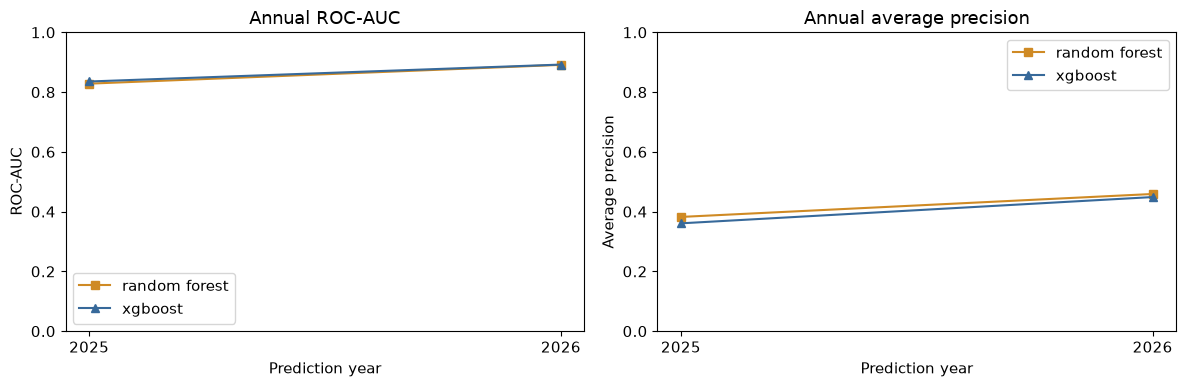

model,random_forest,xgboost
year,,
2025,0.8283,0.8355
2026,0.8911,0.8921


In [12]:
model_names = ["random_forest", "xgboost"]
model_colors = {"random_forest": "#cf8a24", "xgboost": "#37699a"}
model_markers = {"random_forest": "s", "xgboost": "^"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for model_name in model_names:
    rows = evaluation_results[evaluation_results["model"] == model_name].sort_values("year")
    for axis, metric in zip(axes, ["roc_auc", "average_precision"]):
        axis.plot(rows["year"], rows[metric], label=model_name.replace("_", " "),
                  color=model_colors[model_name], marker=model_markers[model_name])
for axis, title, ylabel in zip(axes, ["Annual ROC-AUC", "Annual average precision"], ["ROC-AUC", "Average precision"]):
    axis.set(title=title, xlabel="Prediction year", ylabel=ylabel, xticks=evaluation_years, ylim=(0, 1))
    axis.legend()
plt.tight_layout()
plt.show()
display(evaluation_results.pivot(index="year", columns="model", values="roc_auc").round(4))

### ROC curves
Within a panel, both models are scored on exactly the same test rows.

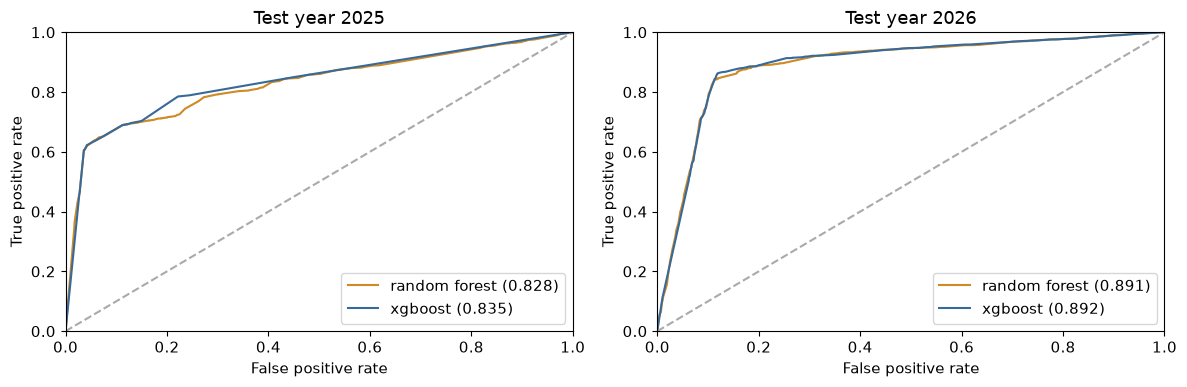

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, year in zip(axes, evaluation_years):
    for model_name in model_names:
        rows = all_predictions[(all_predictions["year"] == year) & (all_predictions["model"] == model_name)]
        false_positive_rate, true_positive_rate, _ = roc_curve(rows["target"], rows["probability"])
        auc = roc_auc_score(rows["target"], rows["probability"])
        axis.plot(false_positive_rate, true_positive_rate, color=model_colors[model_name],
                  label=f"{model_name.replace('_', ' ')} ({auc:.3f})")
    axis.plot([0, 1], [0, 1], "--", color="#aaaaaa")
    axis.set(title=f"Test year {year}", xlabel="False positive rate", ylabel="True positive rate",
             xlim=(0, 1), ylim=(0, 1))
    axis.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Precision–recall and calibration
Pooled curves combine the two historical evaluations and their different fitted
models. They supplement annual AUC; no future-year calibration claim is made.

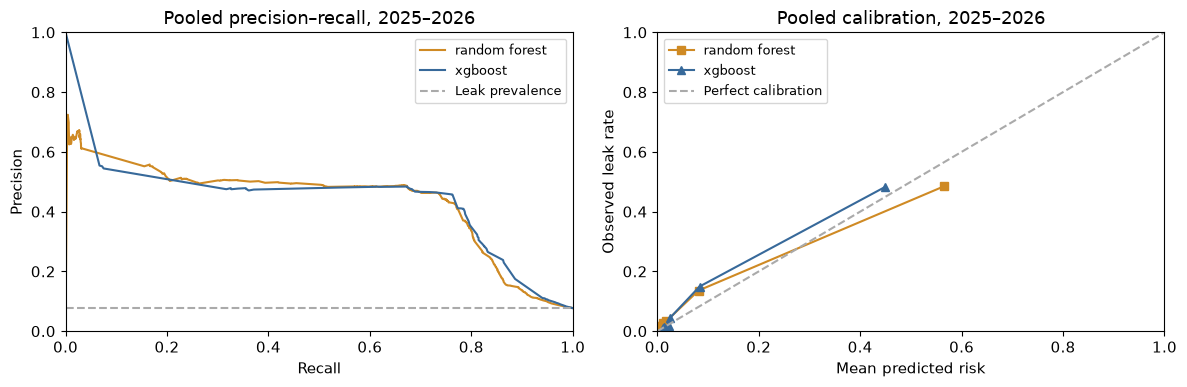

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for model_name in model_names:
    rows = all_predictions[all_predictions["model"] == model_name]
    precision, recall, _ = precision_recall_curve(rows["target"], rows["probability"])
    observed, predicted = calibration_curve(rows["target"], rows["probability"], n_bins=10, strategy="quantile")
    axes[0].plot(recall, precision, color=model_colors[model_name], label=model_name.replace("_", " "))
    axes[1].plot(predicted, observed, color=model_colors[model_name], marker=model_markers[model_name],
                 label=model_name.replace("_", " "))
prevalence = all_predictions[all_predictions["model"] == "xgboost"]["target"].mean()
axes[0].axhline(prevalence, color="#aaaaaa", linestyle="--", label="Leak prevalence")
axes[1].plot([0, 1], [0, 1], "--", color="#aaaaaa", label="Perfect calibration")
axes[0].set(title="Pooled precision–recall, 2025–2026", xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1))
axes[1].set(title="Pooled calibration, 2025–2026", xlabel="Mean predicted risk", ylabel="Observed leak rate", xlim=(0, 1), ylim=(0, 1))
for axis in axes:
    axis.legend(fontsize=9)
plt.tight_layout()
plt.show()

### Classification results
F1, precision and recall use thresholds fixed using earlier validation data.
The confusion matrix combines the winning model's two annual evaluations.

In [15]:
display(evaluation_results[["model", "year", "f1", "precision", "recall", "brier"]].round(4))
winner_predictions = all_predictions[all_predictions["model"] == best_model_name]
labels = winner_predictions["probability"] >= winner_predictions["threshold"]
matrix = confusion_matrix(winner_predictions["target"], labels)
display(pd.DataFrame(matrix, index=["Actual no leak", "Actual leak"],
                     columns=["Predicted no leak", "Predicted leak"]))

,model,year,f1,precision,recall,brier
0,random_forest,2025,0.5448,0.4949,0.6058,0.0387
1,random_forest,2026,0.5740,0.4846,0.7038,0.0647
2,xgboost,2025,0.5322,0.4659,0.6204,0.0403
3,xgboost,2026,0.5728,0.4785,0.7133,0.0633


,Predicted no leak,Predicted leak
Actual no leak,53911,3623
Actual leak,1544,3267


## 7. Fit and save the winning model on all labelled data
After choosing a family, tune that family on the prepared 2020–2025/2026 pair
using the two groups selected for the full training CSV. Refit on all labelled
2020–2026 rows and save one final estimator. This creates no future-year predictions.

In [16]:
full_dir = fold_dir / "full_training"
full_inner = pd.read_csv(full_dir / "inner_train.csv.gz")
full_validation = pd.read_csv(full_dir / "validation.csv.gz")

if best_model_name == "random_forest":
    full_tuning = pd.concat([full_inner, full_validation], ignore_index=True)
    time_split = PredefinedSplit(np.where(full_tuning["year"] == 2026, 0, -1))
    search = GridSearchCV(RandomForestClassifier(random_state=random_seed, n_jobs=4),
                          forest_grid, cv=time_split, scoring="roc_auc", refit=False, n_jobs=1)
    search.fit(full_tuning[final_predictors], full_tuning["target"])
    best_parameters = search.cv_results_["params"][np.argmax(search.cv_results_["mean_test_score"])]
    best_model = RandomForestClassifier(**best_parameters, random_state=random_seed, n_jobs=4)
else:
    final_candidates = []
    for parameters in xgboost_settings:
        model = XGBClassifier(**xgboost_defaults, **parameters, n_estimators=700, early_stopping_rounds=30)
        model.fit(full_inner[final_predictors], full_inner["target"],
                  eval_set=[(full_validation[final_predictors], full_validation["target"])], verbose=False)
        probabilities = model.predict_proba(full_validation[final_predictors])[:, 1]
        final_candidates.append({"parameters": parameters, "trees": model.best_iteration + 1,
                                 "roc_auc": roc_auc_score(full_validation["target"], probabilities),
                                 "average_precision": average_precision_score(full_validation["target"], probabilities)})
    best_final = max(final_candidates, key=lambda row: (row["roc_auc"], row["average_precision"]))
    best_parameters = {**best_final["parameters"], "n_estimators": best_final["trees"]}
    best_model = XGBClassifier(**xgboost_defaults, **best_parameters)

In [17]:
best_model.fit(training_data[final_predictors], training_data["target"])
joblib.dump(best_model, output_dir / "best_model.joblib")
details = {"model": best_model_name, "mean_evaluation_auc": float(leaderboard.iloc[0]["roc_auc"]),
           "evaluation_years": evaluation_years, "training_years": sorted(training_data["year"].unique().tolist()),
           "training_rows": len(training_data), "predictor_columns": final_predictors,
           "parameters": best_parameters, "status": "Two-year reused development comparison"}
(output_dir / "best_model_details.json").write_text(json.dumps(details, indent=2))
evaluation_results.to_csv(output_dir / "annual_scores.csv", index=False)
leaderboard.to_csv(output_dir / "leaderboard.csv")
pd.DataFrame(tuning_rows).to_csv(output_dir / "tuning_results.csv", index=False)
all_predictions.to_csv(output_dir / "historical_predictions.csv.gz", index=False)

reloaded = joblib.load(output_dir / "best_model.joblib")
sample = training_data[final_predictors].head(100)
print("Saved model reproduces probabilities:",
      np.allclose(best_model.predict_proba(sample), reloaded.predict_proba(sample)))
print("Winning model:", best_model_name)
print("Saved:", output_dir / "best_model.joblib")

Saved model reproduces probabilities: True
Winning model: xgboost
Saved: /Users/simondoan/Documents/SFU/STAT 440/Project/P1/results/model_comparison/best_model.joblib
